# Checkpoint comparison — α-only GNN vs combined GNN vs expanded SVM

Three trained models scored over the same three sequence sets, so the numbers are
comparable row by row.

| Key | Checkpoint | What it is |
|---|---|---|
| `gnn_alpha_qsar` | `checkpoints/gnn/gnn_alpha_qsar/` | **new** — GAT + QSAR-12, trained on the α-helix-only set (`data/training/expanded_alpha_only/`, 987 AMP / 2,268 decoy, premade split) |
| `gnn_vae_qsar` | `checkpoints/gnn/gnn_vae_qsar/` | combined — same architecture and feature set, trained on α **and** β AMPs (`data/training/expanded_amps/alpha_and_beta_combined.csv`, 1,064 / 2,272) |
| `svm_no_class_weight` | `checkpoints/svm_no_class_weight/` | expanded SVM — RBF SVC on the same 12 QSAR descriptors, no class weighting, 1,061 / 2,268 |

The two GNNs are architecturally identical (`gat`, 33-dim nodes = `onehot` +
`vae_table`, 3 layers, 64 hidden, `mean_max` pooling, 12 QSAR tabular features).
**The only difference between them is the training set**, which is what this notebook
is measuring.

| Set | Rows | Labels |
|---|---|---|
| `data/sanity_test/sequences.csv` | 31 | 16 AMP / 15 non-AMP — natural AMPs plus the designed `AP*` amphipathic controls |
| `data/proteome_sanity_test/sequences.csv` | 15 | 10 AMP / 5 non-AMP — human proteome fragments |
| `data/Michael_sequences/10-21-wheat-mutations/sequences.csv` | 6 | **none** — the `gld` wheat peptides; predictions only, no true class |

## Reading the two scores

- **σ** — the raw model score. For the GNNs it is the **logit margin**
  `logit_AMP − logit_nonAMP`; for the SVM it is the **signed distance to the
  hyperplane**. Both are signed with σ > 0 favouring AMP, but they are **different
  quantities on different scales** — never compare σ between the SVM and a GNN, and
  compare GNN σ between the two checkpoints only as a rough guide, since the heads
  were trained separately.
- **P(AMP)** — the calibrated probability, and the **only axis comparable across all
  three models**. The GNNs use temperature scaling (the default `--fitting` cascade):
  T = 0.7658 for `gnn_vae_qsar`, T = 0.8207 for `gnn_alpha_qsar`. The SVM uses
  scikit-learn's built-in Platt `predict_proba`.
- **`prediction`** is `+1 / -1` as written by `sequence_analysis`. For the GNNs it is
  `P(AMP) ≥ 0.5`, equivalently σ > 0 under temperature scaling. For the SVM it is
  `svm.predict`, i.e. `sign(σ)`, which can disagree with `P(AMP) ≥ 0.5` by a hair
  because sklearn's Platt fit carries an intercept. The call shown everywhere below is
  always the runner's own `prediction`.

## Reproducing the runs

This notebook reads CSV run artifacts only — no module imports. The nine runs behind
it, from the repo root:

```bash
for d in data/sanity_test data/proteome_sanity_test data/Michael_sequences/10-21-wheat-mutations; do
  python -m sequence_analysis -i $d/sequences.csv --model svm --checkpoint-dir checkpoints/svm_no_class_weight
  python -m sequence_analysis -i $d/sequences.csv --model gnn --gnn-model checkpoints/gnn/gnn_vae_qsar
  python -m sequence_analysis -i $d/sequences.csv --model gnn --gnn-model checkpoints/gnn/gnn_alpha_qsar
done
```

Each writes `<input dir>/results/runs/<ts>/sequence_predictions.csv` plus a
`run_manifest.json`. All three models write into the same `results/runs/` tree, so the
loader below picks runs by the **checkpoint recorded in the manifest** rather than by
timestamp order, and takes the latest run per checkpoint.

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from sklearn.metrics import accuracy_score, matthews_corrcoef


def find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for path in (here, *here.parents):
        if (path / "sequence_analysis").is_dir() and (path / "checkpoints").is_dir():
            return path
    raise FileNotFoundError("Could not locate the repository root.")


ROOT = find_repo_root()

MODEL_ORDER = ["svm_no_class_weight", "gnn_vae_qsar", "gnn_alpha_qsar"]
MODEL_LABEL = {
    "svm_no_class_weight": "Expanded SVM",
    "gnn_vae_qsar": "GNN combined",
    "gnn_alpha_qsar": "GNN alpha-only",
}
MODEL_SHORT = {
    "svm_no_class_weight": "SVM",
    "gnn_vae_qsar": "GNN-comb",
    "gnn_alpha_qsar": "GNN-alpha",
}
MODEL_COLOR = {
    "svm_no_class_weight": "#3f99c0",
    "gnn_vae_qsar": "#2a5fae",
    "gnn_alpha_qsar": "#1b2f6b",
}
MODEL_MARKER = {"svm_no_class_weight": "s", "gnn_vae_qsar": "o", "gnn_alpha_qsar": "^"}

DATASET_ORDER = ["sanity_test", "proteome_sanity_test", "gld_peptides"]
DATASET_DIR = {
    "sanity_test": ROOT / "data" / "sanity_test",
    "proteome_sanity_test": ROOT / "data" / "proteome_sanity_test",
    "gld_peptides": ROOT / "data" / "Michael_sequences" / "10-21-wheat-mutations",
}
DATASET_LABEL = {
    "sanity_test": "sanity_test",
    "proteome_sanity_test": "proteome_sanity_test",
    "gld_peptides": "gld peptides (unlabelled)",
}
DATASET_MARKER = {"sanity_test": "o", "proteome_sanity_test": "s", "gld_peptides": "D"}
LABELED_DATASETS = ["sanity_test", "proteome_sanity_test"]

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.family"] = "monospace"
# TrueType (Type 42) so PDF text stays editable vectors instead of raster outlines.
plt.rcParams["pdf.fonttype"] = 42

SPINE_COLOR = "#2b2b2b"
LABEL_SIZE = 10.5
TITLE_SIZE = 12
THRESHOLD_COLOR = "#c1272d"


def style_axes(ax, grid_axis: str = "y") -> None:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(SPINE_COLOR)
        ax.spines[side].set_linewidth(0.8)
    ax.grid(False)
    ax.grid(axis=grid_axis, linestyle="--", linewidth=0.6, alpha=0.5, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", labelsize=8.5, length=3.5, width=0.8, colors=SPINE_COLOR)


def bare_axes(ax) -> None:
    """Heatmap framing: no grid, no spines, no tick marks."""
    ax.grid(False)
    ax.tick_params(length=0, colors=SPINE_COLOR)
    for spine in ax.spines.values():
        spine.set_visible(False)


def monospace(styler):
    return styler.set_properties(**{"font-family": "monospace", "font-size": "10pt"})

In [2]:
def resolve_runs(data_dir: Path) -> dict[str, Path]:
    """Latest completed sequence_analysis run per checkpoint, keyed off the manifest.

    All three models write into one results/runs tree, so the checkpoint recorded in
    run_manifest.json is the only safe discriminator. Run ids are zero-padded and sort
    lexicographically, so the last match for a checkpoint is its newest run.
    """
    found: dict[str, Path] = {}
    for manifest_path in sorted((data_dir / "results" / "runs").glob("*/run_manifest.json")):
        manifest = json.loads(manifest_path.read_text())
        if manifest.get("status") != "completed":
            continue
        files = manifest["model"]["files"]
        key = "gnn_model" if "gnn_model" in files else "svm_pickle"
        if key not in files:
            continue
        checkpoint = Path(files[key]["path"]).parent.name
        if checkpoint in MODEL_LABEL:
            found[checkpoint] = manifest_path.parent
    return found


def load_dataset(name: str) -> pd.DataFrame:
    runs = resolve_runs(DATASET_DIR[name])
    missing = [checkpoint for checkpoint in MODEL_ORDER if checkpoint not in runs]
    if missing:
        raise FileNotFoundError(
            f"{name}: no completed sequence_analysis run for {missing}. "
            "Run the commands in the cell above first."
        )
    frames = []
    for checkpoint in MODEL_ORDER:
        run_dir = runs[checkpoint]
        manifest = json.loads((run_dir / "run_manifest.json").read_text())
        frame = pd.read_csv(run_dir / "sequence_predictions.csv")
        frame["dataset"] = name
        frame["checkpoint"] = checkpoint
        frame["run_id"] = manifest["run_id"]
        # SVM probabilities come from sklearn's own Platt fit, so the manifest records
        # no fitting method for them.
        frame["fitting"] = manifest["config"]["effective"].get("fitting") or "sklearn_platt"
        frames.append(frame)
    merged = pd.concat(frames, ignore_index=True)
    columns = ["dataset", "checkpoint", "run_id", "fitting", "id", "sequence",
               "prediction", "sigma", "p_amp"]
    if "label" in merged.columns:
        columns.append("label")
    merged = merged[columns].copy()
    merged["length"] = merged["sequence"].str.len()
    return merged


scores = pd.concat([load_dataset(name) for name in DATASET_ORDER], ignore_index=True)

# Every sequence must be scored once by every model, or the paired comparisons below
# would be comparing different peptide sets.
counts = (scores.pivot_table(index="dataset", columns="checkpoint", values="id", aggfunc="count")
          .reindex(index=DATASET_ORDER, columns=MODEL_ORDER))
assert counts.notna().all().all() and (counts.nunique(axis=1) == 1).all(), counts

ROW_COUNT = {dataset: int(counts.loc[dataset].iloc[0]) for dataset in DATASET_ORDER}

for dataset in DATASET_ORDER:
    print(f"{dataset}  ({ROW_COUNT[dataset]} sequences)")
    for checkpoint in MODEL_ORDER:
        row = scores[(scores["dataset"] == dataset) & (scores["checkpoint"] == checkpoint)].iloc[0]
        print(f"    {MODEL_LABEL[checkpoint]:<16} run {row['run_id']:<20} fitting={row['fitting']}")

sanity_test  (31 sequences)
    Expanded SVM     run 2026-11-12_13-05     fitting=sklearn_platt
    GNN combined     run 2026-11-12_13-05_02  fitting=temperature
    GNN alpha-only   run 2026-11-12_13-05_03  fitting=temperature
proteome_sanity_test  (15 sequences)
    Expanded SVM     run 2026-11-12_13-05     fitting=sklearn_platt
    GNN combined     run 2026-11-12_13-05_02  fitting=temperature
    GNN alpha-only   run 2026-11-12_13-06     fitting=temperature
gld_peptides  (6 sequences)
    Expanded SVM     run 2026-11-12_13-05     fitting=sklearn_platt
    GNN combined     run 2026-11-12_13-05_02  fitting=temperature
    GNN alpha-only   run 2026-11-12_13-06     fitting=temperature


### Which peptides the models have already seen

A sanity set is only a sanity check for sequences outside the training table. Each
model's training sequences are read from its own artifact where one exists:

- **Expanded SVM** — `checkpoints/svm_no_class_weight/summary/svm_qsar12_training_descriptors.csv`,
  written at training time, so this is exact.
- **GNN α-only** — `data/training/expanded_alpha_only/AMPs_alpha_{train,validation,test}.csv`,
  corroborated by `gnn_temperature_scaling`, which records `AMPs_alpha_validation.csv`
  as its `val_source`.
- **GNN combined** — `data/training/expanded_amps/alpha_and_beta_combined.csv`. This one
  is **inferred**: `train.py` stores no training-input path in the checkpoint and the
  temperature file holds only `seed`/`val_size`. The table is a 99.8% match to the
  SVM's own recorded training sequences, which is the basis for the identification.

Matching is on the exact sequence string, uppercased — a near-identical homolog is not
caught.

In [3]:
TRAINING_TABLES = {
    "svm_no_class_weight": [
        ROOT / "checkpoints" / "svm_no_class_weight" / "summary" / "svm_qsar12_training_descriptors.csv",
    ],
    "gnn_vae_qsar": [
        ROOT / "data" / "training" / "expanded_amps" / "alpha_and_beta_combined.csv",
    ],
    "gnn_alpha_qsar": [
        ROOT / "data" / "training" / "expanded_alpha_only" / f"AMPs_alpha_{split}.csv"
        for split in ("train", "validation", "test")
    ],
}
SEEN_CODE = {"svm_no_class_weight": "s", "gnn_vae_qsar": "c", "gnn_alpha_qsar": "a"}
TRUE_LABEL = {1: "AMP", 0: "·"}


def training_sequences(checkpoint: str) -> set[str]:
    sequences: set[str] = set()
    for path in TRAINING_TABLES[checkpoint]:
        sequences |= set(pd.read_csv(path)["sequence"].str.strip().str.upper())
    return sequences


TRAINING_SEQUENCES = {checkpoint: training_sequences(checkpoint) for checkpoint in MODEL_ORDER}

scores["in_training"] = [
    row.sequence.strip().upper() in TRAINING_SEQUENCES[row.checkpoint] for row in scores.itertuples()
]

print("Training-set sizes (unique sequences):")
for checkpoint in MODEL_ORDER:
    print(f"    {MODEL_LABEL[checkpoint]:<16} {len(TRAINING_SEQUENCES[checkpoint]):>5}")
print()

seen = scores[scores["in_training"]]
if seen.empty:
    print("No evaluated sequence appears in any training table.")
else:
    overlap = (seen.pivot_table(index=["dataset", "id"], columns="checkpoint",
                                values="in_training", aggfunc="first")
               .reindex(columns=MODEL_ORDER)
               .eq(True)
               .rename(columns=MODEL_SHORT))
    print(f"{len(overlap)} of {len(scores['id'].unique())} evaluated sequences appear in a "
          "training table (True = seen by that model):")
    display(monospace(overlap.style.format("{}")))

Training-set sizes (unique sequences):
    Expanded SVM      3329
    GNN combined      3336
    GNN alpha-only    3255

5 of 52 evaluated sequences appear in a training table (True = seen by that model):


## Prediction tables

One table per set: P(AMP), σ and the call side by side for the three models. `call` is
`+` for AMP and `·` for non-AMP, and `true` uses the same `·` for a non-AMP label.
`seen` flags training overlap — `*` = all three models, otherwise `s` SVM, `c`
combined, `a` α-only. Rows follow the order of the source `sequences.csv`, here and in
every table and figure below that is indexed by peptide.

In [4]:
def wide_table(dataset: str) -> pd.DataFrame:
    frame = scores[scores["dataset"] == dataset]
    probability = frame.pivot(index="id", columns="checkpoint", values="p_amp").reindex(columns=MODEL_ORDER)
    sigma = frame.pivot(index="id", columns="checkpoint", values="sigma").reindex(columns=MODEL_ORDER)
    prediction = frame.pivot(index="id", columns="checkpoint", values="prediction").reindex(columns=MODEL_ORDER)
    training = frame.pivot(index="id", columns="checkpoint", values="in_training").reindex(columns=MODEL_ORDER)
    per_sequence = frame.drop_duplicates("id").set_index("id")
    # pivot sorts its index, so put the rows back in sequences.csv order - which is
    # the order sequence_analysis wrote its prediction rows in.
    csv_order = frame.loc[frame["checkpoint"] == MODEL_ORDER[0], "id"].tolist()

    table = pd.DataFrame(index=probability.index)
    table["length"] = per_sequence["length"]
    if frame["label"].notna().any():
        table["true"] = per_sequence["label"].map(TRUE_LABEL)
    for checkpoint in MODEL_ORDER:
        short = MODEL_SHORT[checkpoint]
        table[f"{short} call"] = np.where(prediction[checkpoint] == 1, "+", "·")
        table[f"{short} P(AMP)"] = probability[checkpoint]
        table[f"{short} sigma"] = sigma[checkpoint]
    table["seen"] = [
        "*" if row.all() else "".join(SEEN_CODE[c] for c in MODEL_ORDER if row[c])
        for _, row in training.iterrows()
    ]
    table = table.loc[csv_order]
    table.index.name = "id"
    return table


PROBABILITY_COLUMNS = [f"{MODEL_SHORT[c]} P(AMP)" for c in MODEL_ORDER]


def show_table(dataset: str) -> None:
    table = wide_table(dataset)
    numeric = [column for column in table.columns if column.endswith(("P(AMP)", "sigma"))]
    styled = (table.style
              .format({column: "{:.3f}" for column in numeric})
              .background_gradient(cmap="RdYlBu_r", vmin=0.0, vmax=1.0, subset=PROBABILITY_COLUMNS)
              .set_caption(f"<b>{DATASET_LABEL[dataset]}</b> &nbsp; (n = {ROW_COUNT[dataset]}) &mdash; "
                           "true and call: AMP / + = AMP, · = non-AMP &nbsp;|&nbsp; "
                           "seen: s = SVM, c = combined, a = alpha-only, * = all three"))
    display(monospace(styled))


for dataset in DATASET_ORDER:
    show_table(dataset)

,length,true,SVM call,SVM P(AMP),SVM sigma,GNN-comb call,GNN-comb P(AMP),GNN-comb sigma,GNN-alpha call,GNN-alpha P(AMP),GNN-alpha sigma,seen
id,,,,,,,,,,,,
Melittin,26,AMP,+,0.723,0.461,+,0.991,3.624,+,0.989,3.698,*
magainin-2,23,AMP,+,0.917,1.172,+,0.997,4.568,+,0.996,4.635,*
HIV_TAT,11,AMP,+,0.913,1.146,+,0.974,2.763,+,0.997,4.736,
R9,9,AMP,+,0.670,0.338,+,0.972,2.729,+,1.000,7.244,
protegrin-1,18,AMP,+,0.931,1.270,+,0.999,5.207,+,0.800,1.135,sc
H4N,24,AMP,+,0.980,1.910,+,0.943,2.144,+,0.971,2.879,
H2A-1,10,AMP,+,0.873,0.937,+,0.985,3.197,+,0.993,4.034,
H2A-3,17,·,·,0.071,-1.278,·,0.064,-2.055,·,0.073,-2.087,
H2A-3m,17,·,·,0.225,-0.622,·,0.197,-1.075,+,0.840,1.361,


,length,true,SVM call,SVM P(AMP),SVM sigma,GNN-comb call,GNN-comb P(AMP),GNN-comb sigma,GNN-alpha call,GNN-alpha P(AMP),GNN-alpha sigma,seen
id,,,,,,,,,,,,
DFNA5,20,AMP,+,0.717,0.447,+,0.590,0.278,+,0.875,1.594,
DCTN4,21,AMP,+,0.997,2.780,+,0.999,5.061,+,0.998,4.960,
RPL41,14,AMP,+,0.815,0.718,+,0.961,2.460,+,0.995,4.277,
PSMG2,22,AMP,+,0.867,0.910,+,0.877,1.501,+,0.936,2.196,
GLB1,18,AMP,·,0.322,-0.380,+,0.795,1.037,+,0.872,1.572,
RPS4X,13,AMP,·,0.105,-1.071,+,0.613,0.352,+,0.926,2.074,
PPP1CB,12,AMP,+,0.829,0.766,·,0.342,-0.500,+,0.985,3.448,
CHMP2A,11,AMP,+,0.705,0.418,+,0.938,2.078,+,0.976,3.052,
ETS1,26,AMP,+,0.910,1.129,+,0.911,1.778,+,0.939,2.243,


,length,SVM call,SVM P(AMP),SVM sigma,GNN-comb call,GNN-comb P(AMP),GNN-comb sigma,GNN-alpha call,GNN-alpha P(AMP),GNN-alpha sigma,seen
id,,,,,,,,,,,
gld-1,19,·,0.397,-0.220,·,0.081,-1.859,·,0.425,-0.249,
gld-1A,22,·,0.394,-0.227,·,0.153,-1.310,·,0.231,-0.989,
gld-2,19,·,0.218,-0.642,·,0.038,-2.470,·,0.270,-0.815,
gld-3,19,·,0.112,-1.032,·,0.026,-2.785,·,0.231,-0.985,
gld-4,23,+,0.841,0.809,+,0.588,0.272,+,0.580,0.266,
gld-4A,23,·,0.466,-0.080,·,0.055,-2.173,·,0.065,-2.184,


## Accuracy

The fraction of calls matching the true label, using each model's own `prediction`
column, on the two labelled sets. One flipped call moves a bar by 0.032 on
`sanity_test` and 0.067 on `proteome_sanity_test`, so read the gaps as directional.

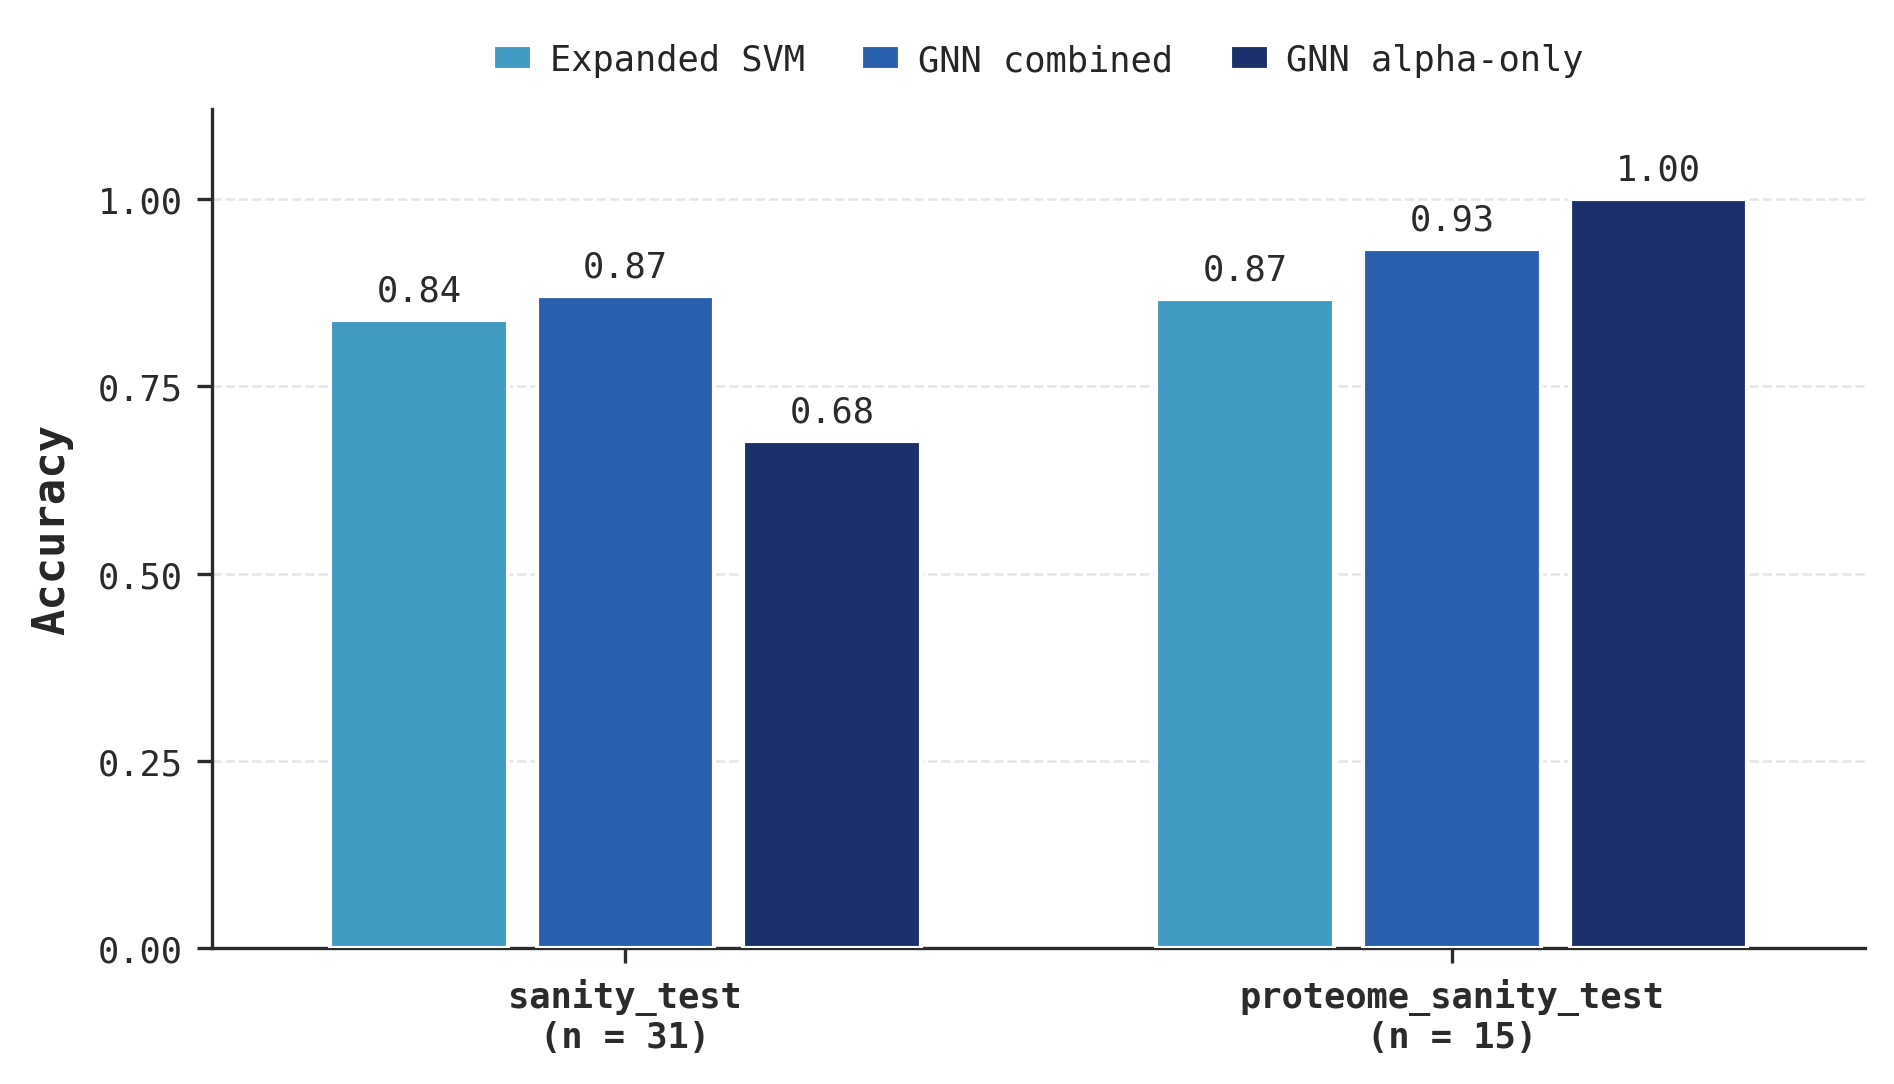

In [5]:
def accuracy_of(dataset: str, checkpoint: str) -> float:
    frame = scores[(scores["dataset"] == dataset) & (scores["checkpoint"] == checkpoint)]
    return accuracy_score((frame["label"] == 1).astype(int), (frame["prediction"] == 1).astype(int))


accuracy = pd.DataFrame(
    [[accuracy_of(dataset, checkpoint) for checkpoint in MODEL_ORDER] for dataset in LABELED_DATASETS],
    index=LABELED_DATASETS, columns=MODEL_ORDER,
)

figure, axis = plt.subplots(figsize=(6.2, 3.5), dpi=300, layout="constrained")
positions = np.arange(len(LABELED_DATASETS))
width = 0.25

for offset, checkpoint in enumerate(MODEL_ORDER):
    bars = axis.bar(positions + (offset - 1) * width, accuracy[checkpoint], width * 0.86,
                    color=MODEL_COLOR[checkpoint], edgecolor="white", linewidth=1.0,
                    label=MODEL_LABEL[checkpoint], zorder=3)
    axis.bar_label(bars, fmt="%.2f", fontsize=8.5, padding=3, color=SPINE_COLOR)

axis.set_xticks(positions, [f"{DATASET_LABEL[dataset]}\n(n = {ROW_COUNT[dataset]})"
                            for dataset in LABELED_DATASETS], fontsize=9.5, fontweight="bold")
axis.set_yticks(np.arange(0, 1.01, 0.25))
axis.set_ylim(0, 1.12)
axis.set_xlim(-0.5, 1.5)
axis.set_ylabel("Accuracy", fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
axis.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, fontsize=8.5,
            frameon=False, columnspacing=1.6, handlelength=1.1, handletextpad=0.5)
style_axes(axis)
plt.show()

## Score distributions by true class

The separation each model achieves, per labelled set. One column per model; the dashed
line is the 0.5 decision threshold, so a point on the wrong side of it is a
misclassification and the two clouds should sit on opposite sides. Open markers are
sequences in that model's own training table.

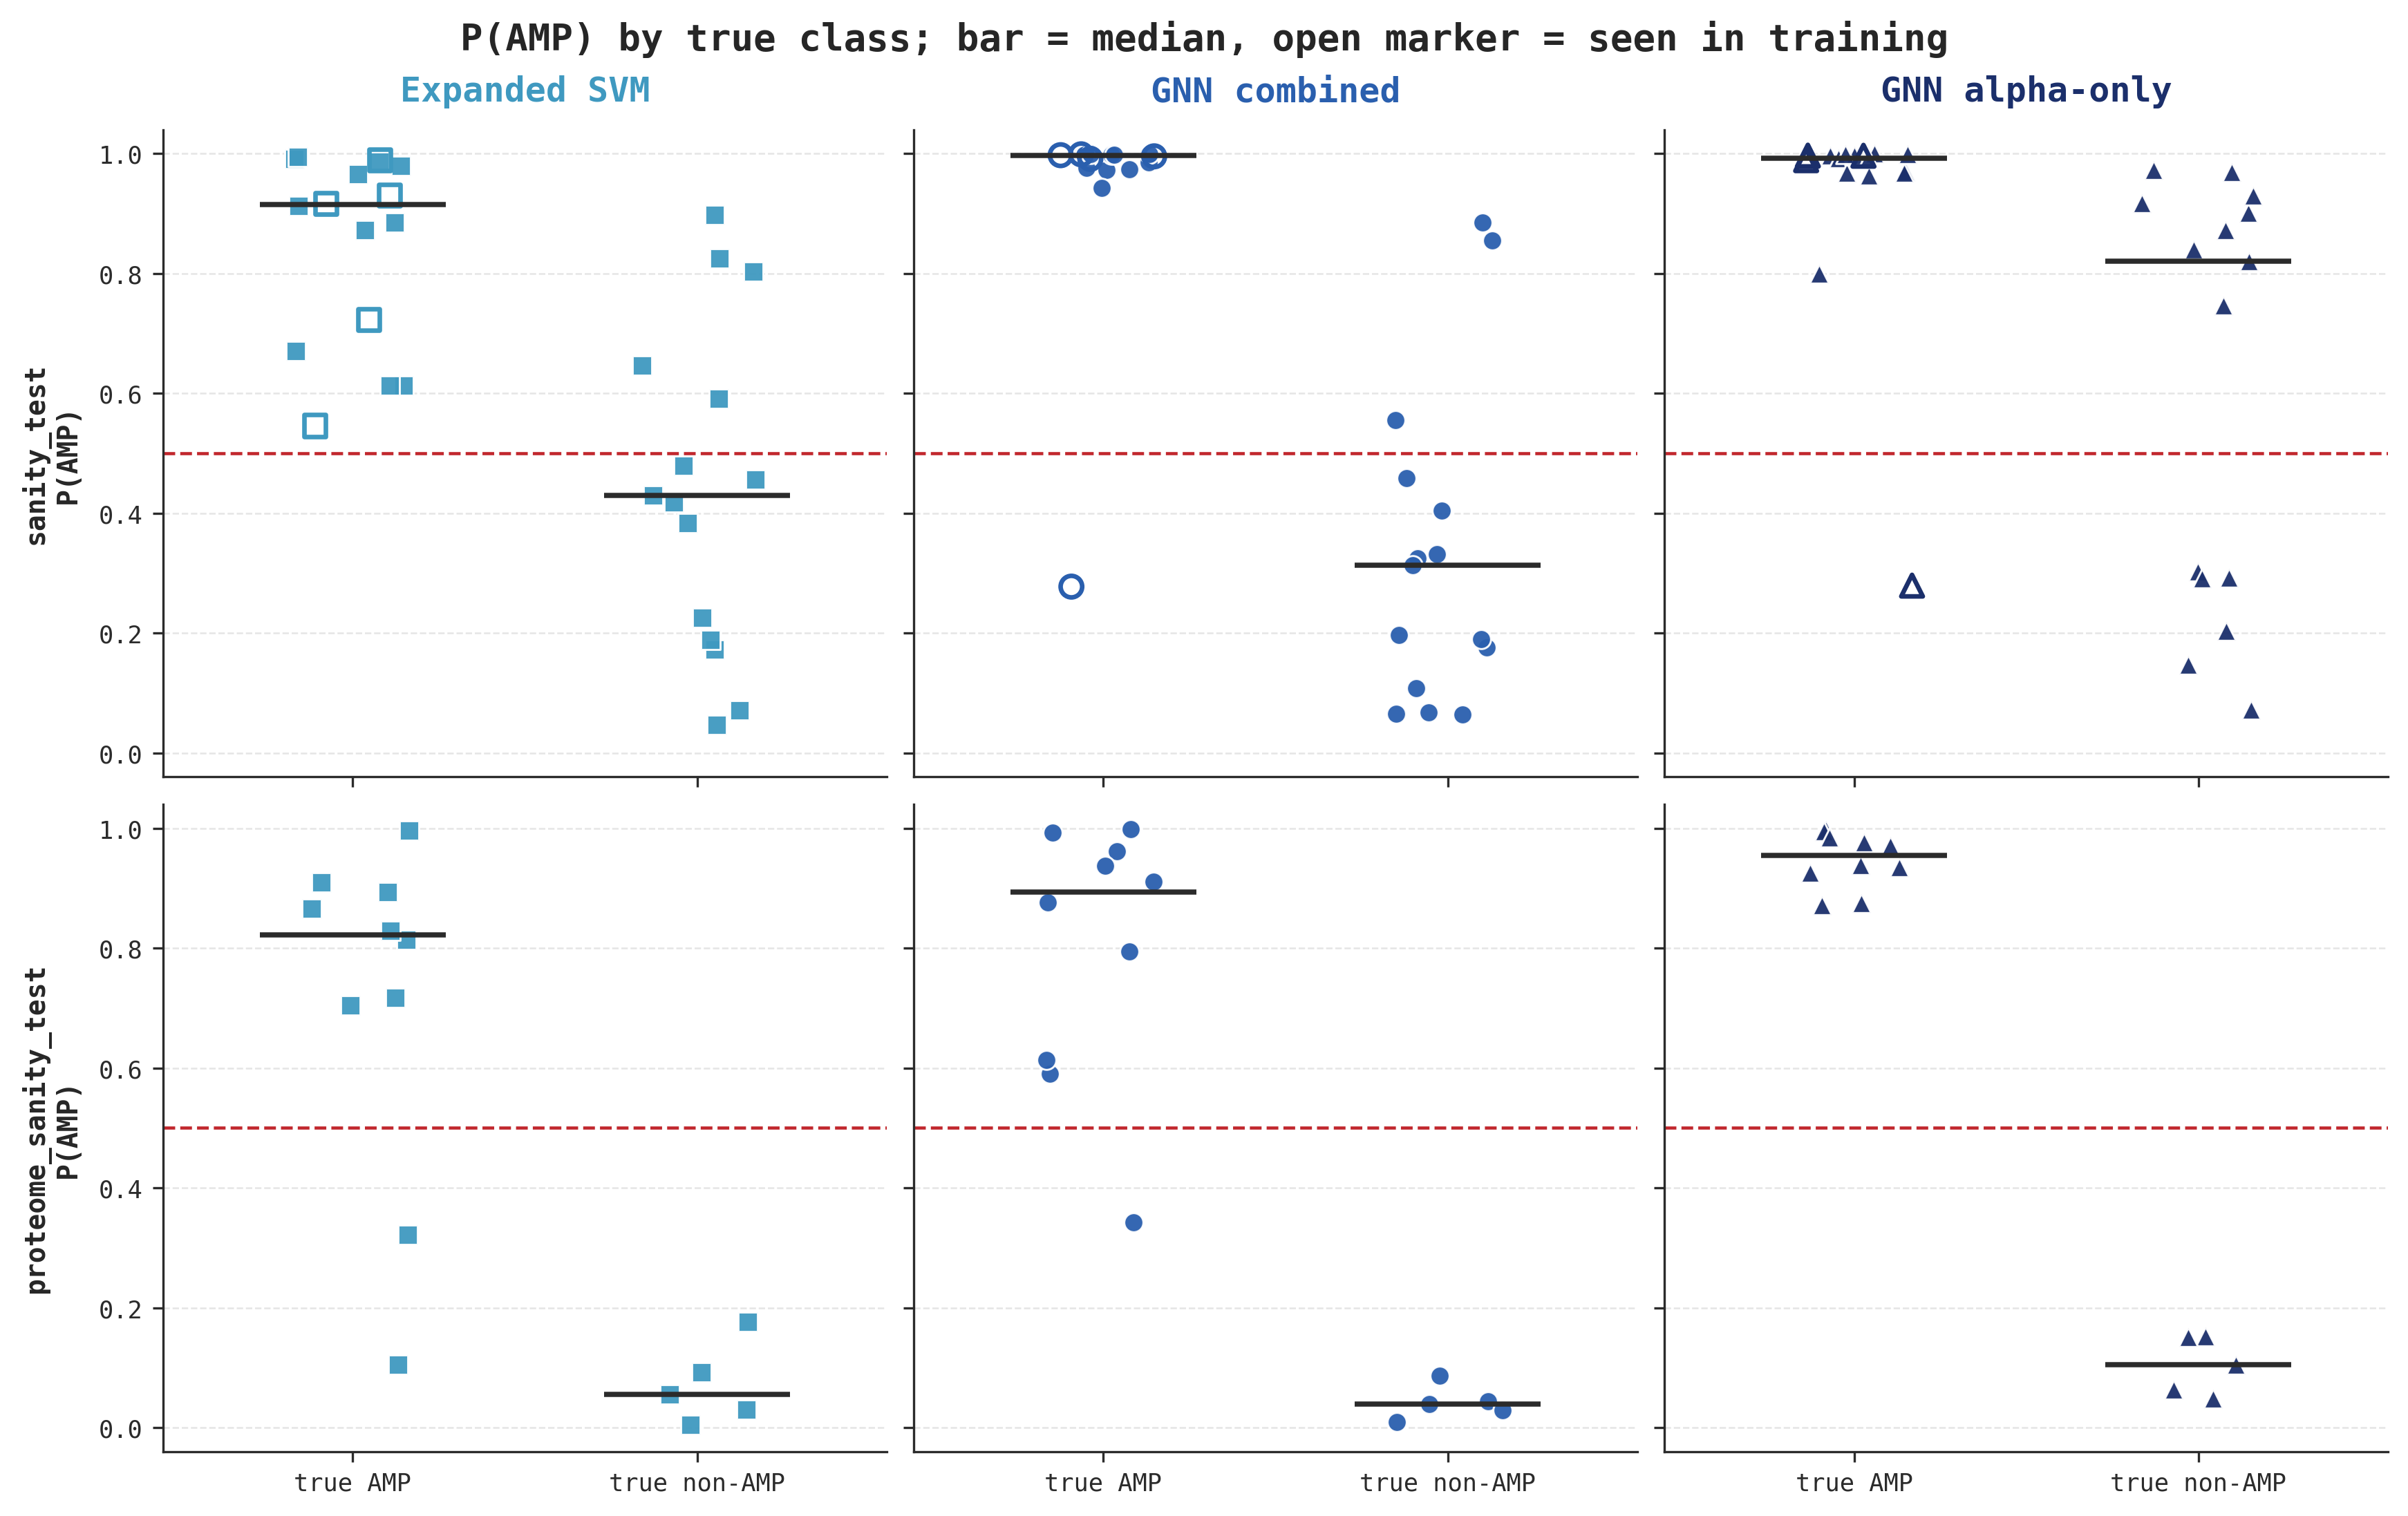

In [6]:
figure, axes = plt.subplots(len(LABELED_DATASETS), len(MODEL_ORDER), figsize=(11.5, 7.2), dpi=300,
                            sharex=True, sharey=True, layout="constrained")
rng = np.random.default_rng(0)
CLASS_POSITION = {1: 0.0, 0: 1.0}
CLASS_LABEL = {1: "true AMP", 0: "true non-AMP"}

for row_index, dataset in enumerate(LABELED_DATASETS):
    for column_index, checkpoint in enumerate(MODEL_ORDER):
        axis = axes[row_index, column_index]
        frame = scores[(scores["dataset"] == dataset) & (scores["checkpoint"] == checkpoint)]
        for true_class, position in CLASS_POSITION.items():
            cell = frame[frame["label"] == true_class]
            jitter = position + rng.uniform(-0.17, 0.17, len(cell))
            fresh = ~cell["in_training"].to_numpy()
            axis.scatter(jitter[fresh], cell.loc[fresh, "p_amp"], s=44,
                         color=MODEL_COLOR[checkpoint], edgecolor="white", linewidth=0.7,
                         marker=MODEL_MARKER[checkpoint], zorder=3, alpha=0.95)
            axis.scatter(jitter[~fresh], cell.loc[~fresh, "p_amp"], s=56, facecolor="none",
                         edgecolor=MODEL_COLOR[checkpoint], linewidth=1.6,
                         marker=MODEL_MARKER[checkpoint], zorder=4)
            axis.hlines(cell["p_amp"].median(), position - 0.27, position + 0.27,
                        color=SPINE_COLOR, linewidth=1.8, zorder=5)
        axis.axhline(0.5, color=THRESHOLD_COLOR, linestyle="--", linewidth=1.1, zorder=2)
        axis.set_xticks(list(CLASS_POSITION.values()),
                        [CLASS_LABEL[c] for c in CLASS_POSITION], fontsize=8.5)
        axis.set_xlim(-0.55, 1.55)
        axis.set_ylim(-0.04, 1.04)
        if row_index == 0:
            axis.set_title(MODEL_LABEL[checkpoint], fontsize=TITLE_SIZE, fontweight="bold",
                           pad=10, color=MODEL_COLOR[checkpoint])
        if column_index == 0:
            axis.set_ylabel(f"{DATASET_LABEL[dataset]}\nP(AMP)", fontsize=9.5,
                            fontweight="bold", labelpad=6)
        style_axes(axis)

figure.suptitle("P(AMP) by true class; bar = median, open marker = seen in training",
                fontsize=TITLE_SIZE + 1, fontweight="bold")
plt.show()

## Confusion matrices

Where each model's errors actually sit. Counts, with the fraction of that true class in
parentheses; shading is the row fraction.

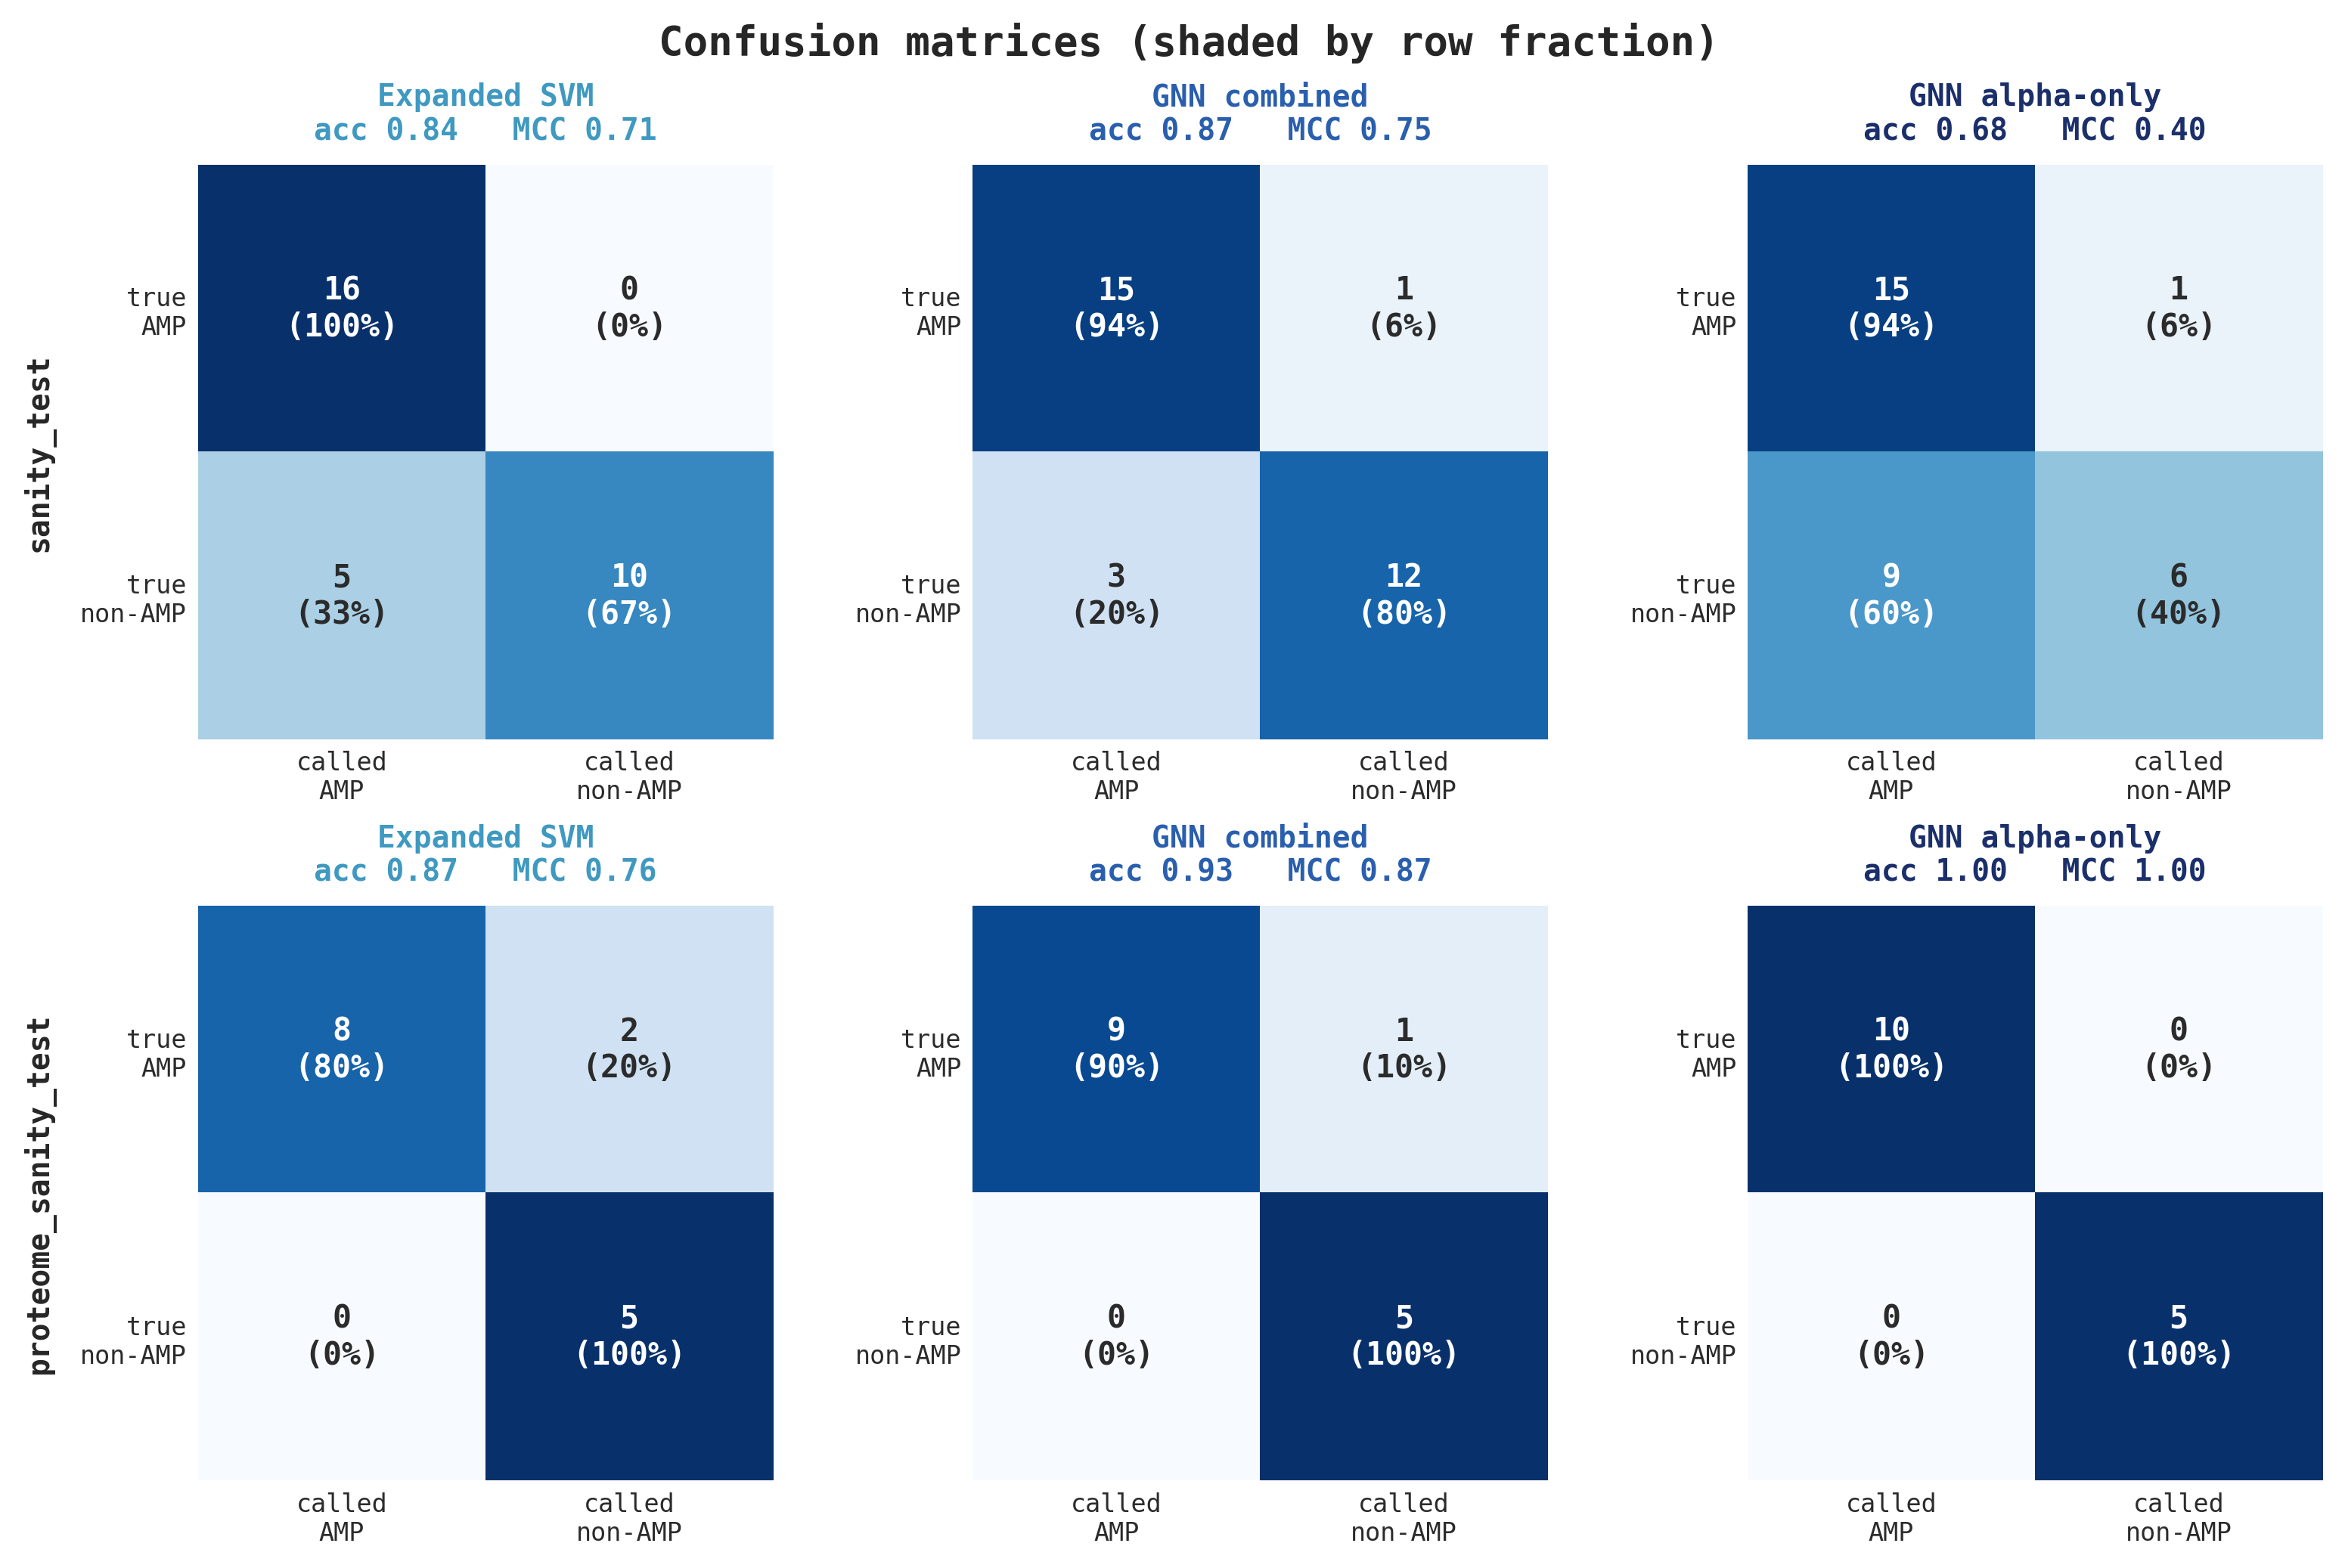

In [7]:
figure, axes = plt.subplots(len(LABELED_DATASETS), len(MODEL_ORDER), figsize=(10.5, 6.8), dpi=300,
                            layout="constrained")

for row_index, dataset in enumerate(LABELED_DATASETS):
    for column_index, checkpoint in enumerate(MODEL_ORDER):
        axis = axes[row_index, column_index]
        frame = scores[(scores["dataset"] == dataset) & (scores["checkpoint"] == checkpoint)]
        truth = (frame["label"] == 1).astype(int)
        call = (frame["prediction"] == 1).astype(int)
        # Rows: true AMP, true non-AMP. Columns: called AMP, called non-AMP.
        matrix = np.array([
            [((truth == 1) & (call == 1)).sum(), ((truth == 1) & (call == 0)).sum()],
            [((truth == 0) & (call == 1)).sum(), ((truth == 0) & (call == 0)).sum()],
        ], dtype=float)
        fractions = matrix / matrix.sum(axis=1, keepdims=True)

        axis.imshow(fractions, cmap="Blues", vmin=0.0, vmax=1.0)
        for row in range(2):
            for column in range(2):
                axis.text(column, row, f"{int(matrix[row, column])}\n({fractions[row, column]:.0%})",
                          ha="center", va="center", fontsize=10, fontweight="bold",
                          color="white" if fractions[row, column] > 0.55 else SPINE_COLOR)
        axis.set_xticks([0, 1], ["called\nAMP", "called\nnon-AMP"], fontsize=8)
        axis.set_yticks([0, 1], ["true\nAMP", "true\nnon-AMP"], fontsize=8)
        accuracy = accuracy_score(truth, call)
        mcc = matthews_corrcoef(truth, call)
        axis.set_title(f"{MODEL_LABEL[checkpoint]}\nacc {accuracy:.2f}   MCC {mcc:.2f}",
                       fontsize=9.5, fontweight="bold", pad=8, color=MODEL_COLOR[checkpoint])
        if column_index == 0:
            axis.set_ylabel(DATASET_LABEL[dataset], fontsize=9.5, fontweight="bold", labelpad=8)
        bare_axes(axis)

figure.suptitle("Confusion matrices (shaded by row fraction)",
                fontsize=TITLE_SIZE + 1, fontweight="bold")
plt.show()

## Model against model

Pairwise P(AMP) — every peptide of all three sets on one panel per pair. The dotted
diagonal is perfect agreement; the grey quadrants are where the two models make
**opposite calls**. Marker shape is the set, and a red ring marks a peptide the pair
disagrees on.

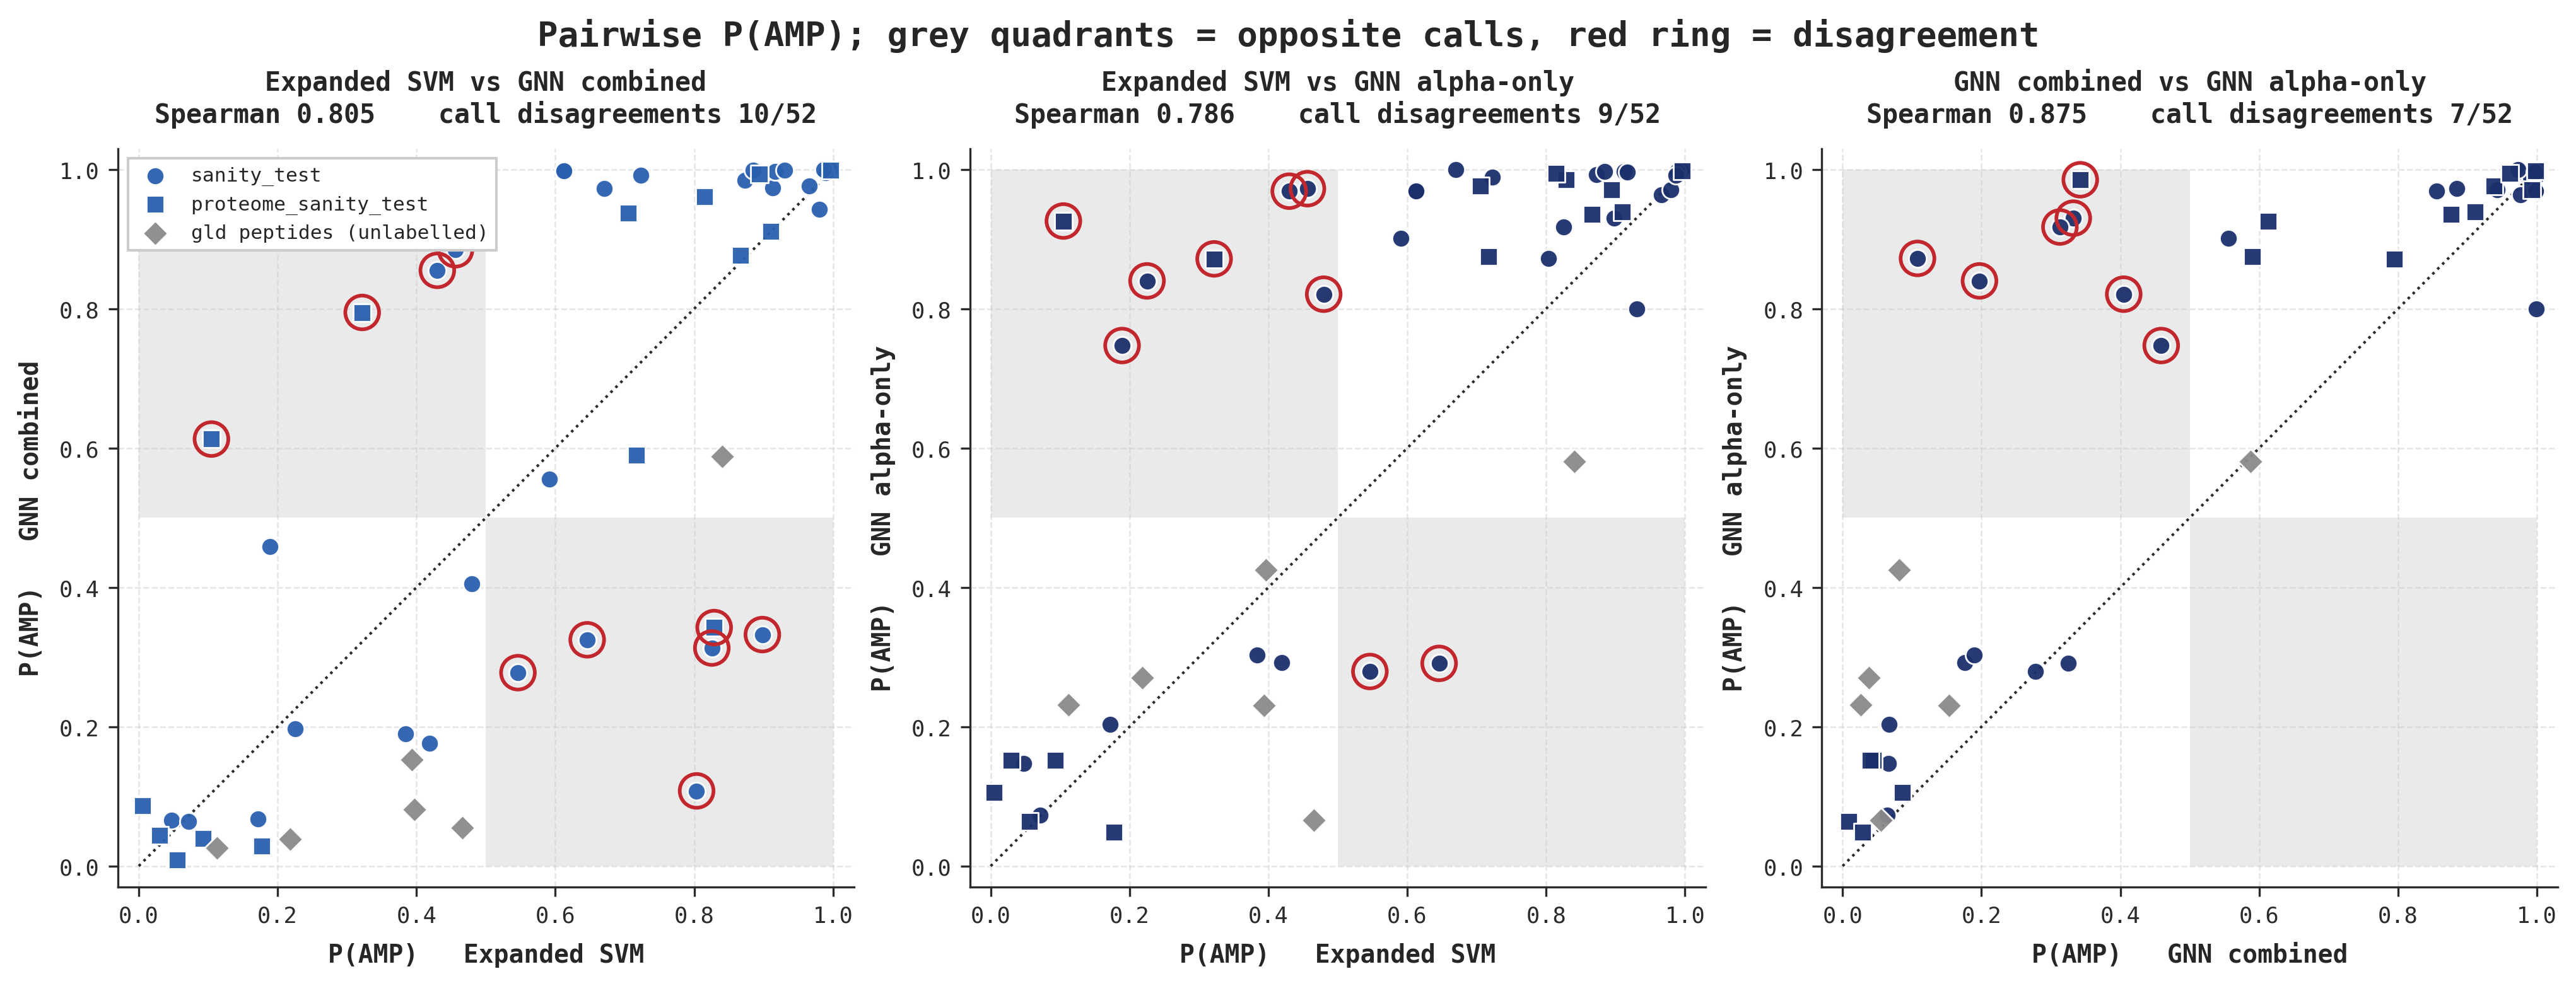

In [8]:
PAIRS = [("svm_no_class_weight", "gnn_vae_qsar"),
         ("svm_no_class_weight", "gnn_alpha_qsar"),
         ("gnn_vae_qsar", "gnn_alpha_qsar")]

wide = scores.pivot_table(index=["dataset", "id"], columns="checkpoint",
                          values=["p_amp", "prediction"])

figure, axes = plt.subplots(1, len(PAIRS), figsize=(13.5, 5.1), dpi=300, layout="constrained")

for axis, (left, right) in zip(axes, PAIRS):
    probability_left = wide[("p_amp", left)]
    probability_right = wide[("p_amp", right)]
    disagree = wide[("prediction", left)] != wide[("prediction", right)]

    axis.add_patch(Rectangle((0.0, 0.5), 0.5, 0.5, color="#d9d9d9", alpha=0.55, linewidth=0, zorder=0))
    axis.add_patch(Rectangle((0.5, 0.0), 0.5, 0.5, color="#d9d9d9", alpha=0.55, linewidth=0, zorder=0))
    axis.plot([0, 1], [0, 1], color=SPINE_COLOR, linestyle=":", linewidth=1.0, zorder=1)

    for dataset in DATASET_ORDER:
        rows = probability_left.index.get_level_values("dataset") == dataset
        axis.scatter(probability_left[rows], probability_right[rows], s=46,
                     color="#8a8a8a" if dataset == "gld_peptides" else MODEL_COLOR[right],
                     marker=DATASET_MARKER[dataset], edgecolor="white", linewidth=0.7,
                     label=DATASET_LABEL[dataset], zorder=3, alpha=0.95)
    axis.scatter(probability_left[disagree], probability_right[disagree], s=165, facecolor="none",
                 edgecolor=THRESHOLD_COLOR, linewidth=1.4, zorder=4)

    spearman = probability_left.corr(probability_right, method="spearman")
    axis.set_xlabel(f"P(AMP)   {MODEL_LABEL[left]}", fontsize=9.5, fontweight="bold", labelpad=6)
    axis.set_ylabel(f"P(AMP)   {MODEL_LABEL[right]}", fontsize=9.5, fontweight="bold", labelpad=6)
    axis.set_title(f"{MODEL_LABEL[left]} vs {MODEL_LABEL[right]}\n"
                   f"Spearman {spearman:.3f}    call disagreements "
                   f"{int(disagree.sum())}/{len(disagree)}",
                   fontsize=10, fontweight="bold", pad=10)
    axis.set_xlim(-0.03, 1.03)
    axis.set_ylim(-0.03, 1.03)
    style_axes(axis, grid_axis="both")

axes[0].legend(loc="upper left", fontsize=7.5, frameon=True, fancybox=False, framealpha=1)
figure.suptitle("Pairwise P(AMP); grey quadrants = opposite calls, red ring = disagreement",
                fontsize=TITLE_SIZE + 1, fontweight="bold")
plt.show()

### The disagreements, listed

Every peptide where the three models do not all agree, with how each scored it, in
`sequences.csv` order. `spread` is the range of P(AMP) across the three. This is the
whole substantive difference between the checkpoints.

In [9]:
calls = wide["prediction"].reindex(columns=MODEL_ORDER)
probabilities = wide["p_amp"].reindex(columns=MODEL_ORDER)
split = calls.nunique(axis=1) > 1
per_sequence = scores.drop_duplicates(["dataset", "id"]).set_index(["dataset", "id"])

disagreements = pd.DataFrame(index=calls.index[split])
disagreements["length"] = per_sequence["length"]
disagreements["true"] = per_sequence["label"].map(TRUE_LABEL).fillna("?")
for checkpoint in MODEL_ORDER:
    short = MODEL_SHORT[checkpoint]
    disagreements[f"{short} call"] = np.where(calls.loc[split, checkpoint] == 1, "AMP", "non-AMP")
    disagreements[f"{short} P"] = probabilities.loc[split, checkpoint]
disagreements["spread"] = probabilities.loc[split].max(axis=1) - probabilities.loc[split].min(axis=1)
CSV_ORDER = [(dataset, name) for dataset in DATASET_ORDER for name in wide_table(dataset).index]
disagreements = disagreements.reindex([key for key in CSV_ORDER if key in disagreements.index])

print(f"{int(split.sum())} of {len(calls)} peptides split the three models "
      f"({len(calls) - int(split.sum())} unanimous).")
display(monospace(disagreements.style
                  .format({"spread": "{:.3f}",
                           **{f"{MODEL_SHORT[c]} P": "{:.3f}" for c in MODEL_ORDER}})
                  .background_gradient(cmap="Oranges", subset=["spread"], vmin=0.0, vmax=1.0)))

13 of 52 peptides split the three models (39 unanimous).


## The gld peptides

No true class, so this is predictions only. Left panel is P(AMP) with the 0.5 threshold
marked; right panel is σ, which is **not** comparable between the SVM and the GNNs
(hyperplane distance vs logit margin) and is shown per model only to indicate how far
from its own boundary each call sits.

Bars are in `sequences.csv` order, which is the order the set was designed in:
`gld-1` → `gld-2` → `gld-3` walk cationic residues out of the lead 19-mer, and
`gld-1A` / `gld-4A` are the cysteine→alanine variants of `gld-1` / `gld-4`. Reading the
bars pairwise is what the set was built for.

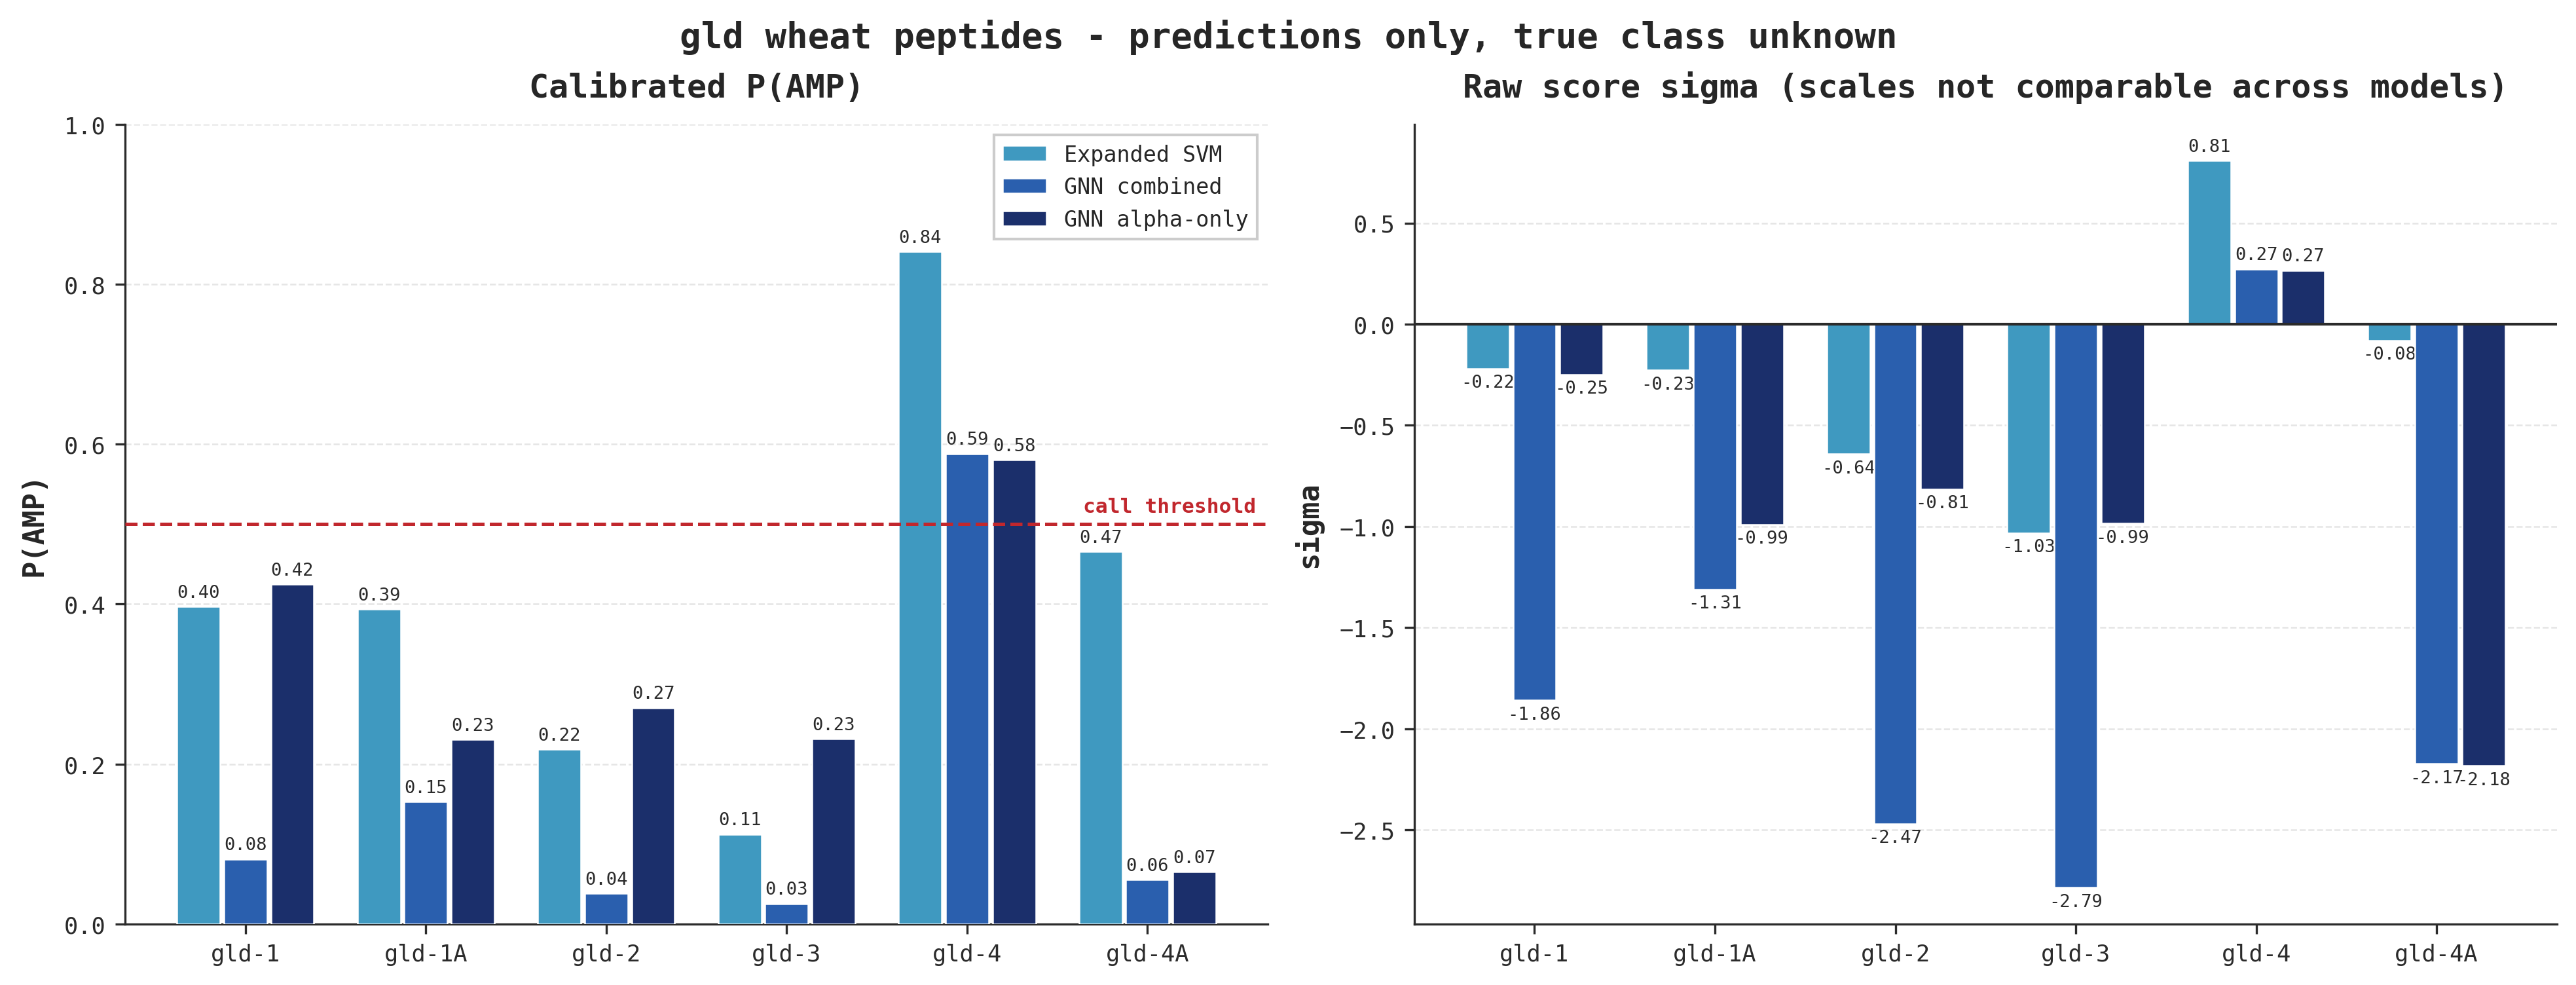

,length,sequence,SVM call,SVM P(AMP),SVM sigma,GNN-comb call,GNN-comb P(AMP),GNN-comb sigma,GNN-alpha call,GNN-alpha P(AMP),GNN-alpha sigma,seen
id,,,,,,,,,,,,
gld-1,19,LWQIPEQSRCQAIHNVVHA,·,0.397,-0.220,·,0.081,-1.859,·,0.425,-0.249,
gld-1A,22,LAAQLWQIPEQSRAQAIHNVVH,·,0.394,-0.227,·,0.153,-1.310,·,0.231,-0.989,
gld-2,19,LWQIPEQSQCQAIHNVVHA,·,0.218,-0.642,·,0.038,-2.470,·,0.270,-0.815,
gld-3,19,LWQIPEQSQCQAIHNVVQA,·,0.112,-1.032,·,0.026,-2.785,·,0.231,-0.985,
gld-4,23,RCCQQLRDVSAKCRSVAVSQVAR,+,0.841,0.809,+,0.588,0.272,+,0.580,0.266,
gld-4A,23,RAAQQLRDVSAKARSVAVSQVAR,·,0.466,-0.080,·,0.055,-2.173,·,0.065,-2.184,


gld-1    gld-1 — optimized 19-mer from α-gliadin NRR1 (the lead ISG); distal to the celiac 33-mer
gld-1A   gld-1A — gld-1 variant with all cysteines → alanine
gld-2    gld-2 — single mutation of gld-1 (cationic R → Q) to reduce cationic charge
gld-3    gld-3 — double mutation of gld-1 (two cationic residues → Q)
gld-4    gld-4 — cognate ISG from wheat HMW glutenin subunit 12 (core of SEQ 12)
gld-4A   gld-4A — gld-4 variant with cysteines → alanine


In [10]:
gld = scores[scores["dataset"] == "gld_peptides"]
order = wide_table("gld_peptides").index.tolist()

figure, axes = plt.subplots(1, 2, figsize=(13.0, 4.9), dpi=300, layout="constrained")
positions = np.arange(len(order))
width = 0.26

for value, axis, label in (("p_amp", axes[0], "P(AMP)"), ("sigma", axes[1], "sigma")):
    for offset, checkpoint in enumerate(MODEL_ORDER):
        cell = gld[gld["checkpoint"] == checkpoint].set_index("id").reindex(order)
        bars = axis.bar(positions + (offset - 1) * width, cell[value].to_numpy(dtype=float),
                        width * 0.92, color=MODEL_COLOR[checkpoint], edgecolor="white",
                        linewidth=0.6, label=MODEL_LABEL[checkpoint], zorder=3)
        axis.bar_label(bars, fmt="%.2f", fontsize=6.5, padding=2, color=SPINE_COLOR)
    axis.set_xticks(positions, order, fontsize=9.5)
    axis.set_ylabel(label, fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
    style_axes(axis)

axes[0].axhline(0.5, color=THRESHOLD_COLOR, linestyle="--", linewidth=1.2, zorder=4)
axes[0].text(len(order) - 0.4, 0.515, "call threshold", fontsize=7.5, color=THRESHOLD_COLOR,
             ha="right", fontweight="bold")
axes[0].set_ylim(0, 1.0)
axes[0].set_title("Calibrated P(AMP)", fontsize=TITLE_SIZE, fontweight="bold", pad=10)
axes[1].axhline(0.0, color=SPINE_COLOR, linewidth=1.0, zorder=4)
axes[1].set_title("Raw score sigma (scales not comparable across models)",
                  fontsize=TITLE_SIZE, fontweight="bold", pad=10)
axes[0].legend(loc="upper right", fontsize=8, frameon=True, fancybox=False, framealpha=1)
figure.suptitle("gld wheat peptides - predictions only, true class unknown",
                fontsize=TITLE_SIZE + 1, fontweight="bold")
plt.show()

design = pd.read_csv(DATASET_DIR["gld_peptides"] / "sequences.csv").set_index("id")
gld_table = wide_table("gld_peptides")
gld_table.insert(1, "sequence", design["sequence"])
numeric = [column for column in gld_table.columns if column.endswith(("P(AMP)", "sigma"))]
display(monospace(gld_table.style
                  .format({column: "{:.3f}" for column in numeric})
                  .background_gradient(cmap="RdYlBu_r", vmin=0.0, vmax=1.0,
                                       subset=PROBABILITY_COLUMNS)))
for name in order:
    print(f"{name:<8} {design.loc[name, 'description']}")

## Caveats

- **Sample size.** 31 + 15 labelled rows. Every metric gap here is worth one or two
  flips; none of it is a significance claim.
- **Training overlap.** Five `sanity_test` peptides sit in the training tables (four for
  the α-only model). They are marked in every table and figure; in-sample rows flatter
  whichever model saw them.
- **The `AP*` controls are the interesting part of `sanity_test`.** They are designed
  amphipathic α-helical peptides labelled non-AMP — exactly the shape the α-only
  training set is made of. Read the α-only model's behaviour on them before concluding
  anything from its headline accuracy.
- **σ is not a shared axis.** SVM σ is a hyperplane distance, GNN σ is a logit margin.
  Only P(AMP) is comparable across models, and even that rests on two different
  calibration methods fit on two different validation sets.
- **Calibration choice moves the hard call.** These GNN runs use temperature scaling,
  the default cascade. Under Platt the P = 0.5 crossing moves off σ = 0
  (`gnn_vae_qsar`: σ = 1.340; `gnn_alpha_qsar`: σ = 1.763), which flips calls near the
  boundary. Re-run with `-f platt` to see that, but do not mix the two in one
  comparison.
- **The combined checkpoint's training table is inferred,** not recorded in the
  checkpoint — see the training-overlap section.